# EmbeddingGemma 2：Google Colab マルチモーダル検索デモ（日本語）

**このノートブックで試せること**

1. 日本語の意味検索（テキスト → テキスト）
2. 日本語の質問から写真を探す（テキスト → 画像）
3. 128 / 256 / 512 / 768 次元による検索順位の比較（MRL）
4. 自分の画像をアップロードして検索
5. **オプション**：音声 → テキスト、動画 → テキストの照合
6. **発展**：障害報告書の意味検索（Incident Intelligence の入口）

### はじめに

- Colabの **[ランタイム] → [ランタイムのタイプを変更] → [T4 GPU]**（可能ならL4 GPU）を選択します。
- 上から順にセルを実行してください。最初の実行でモデルをダウンロードします（ネット接続が必要）。
- APIキーは通常必要ありません。モデルにアクセス制限が発生した場合のみHugging Face認証を追加してください。
- EmbeddingGemma 2は**文章生成モデルではなく、768次元のベクトルを作るモデル**です。このノートブックではベクトルの類似度による検索を行います。
- **T4 GPUでは bfloat16 非対応なので float32 を使用します。float16 を使わないでください。**
- **CUDA 13のtorchcodec読み込みエラー対策済み**：インストールセルはTorchCodecのCPU版を使います。
- 初期状態では音声エンコーダを読み込まず、GPUメモリを節約します。音声も試す場合は「2. モデルの読み込み」の `ENABLE_AUDIO=True` に変え、モデル読み込み以降のセルを再実行してください。

参照： [公式マルチモーダルガイド](https://ai.google.dev/gemma/docs/embeddinggemma/multimodal-embeddinggemma-with-sentence-transformers) ／ [公式テキストガイド](https://ai.google.dev/gemma/docs/embeddinggemma/inference-embeddinggemma-with-sentence-transformers) ／ [モデル](https://huggingface.co/google/embeddinggemma-2)

## 1. ライブラリのインストールとCUDA互換性の修正

Colab標準のPyTorchは変更せず、TorchCodecだけCPU版に揃えます。`libnvrtc.so.13` の不一致を回避するためです。EmbeddingGemma 2のEmbedding生成は引き続きGPUで実施できます。

**既に同じランタイムで失敗した場合**は、このセル実行後に「ランタイム → セッションを再起動」して、上から順番に実行してください。


In [1]:
# Colab標準のPyTorchを維持し、必要なPythonパッケージを追加
%pip -q install -U sentence-transformers transformers pillow requests pandas matplotlib soundfile

# torchcodecのCUDA版がlibnvrtc.so.13を要求する問題を防ぐため、
# PyTorchのバージョンに対応したCPU版torchcodecを導入します。
# EmbeddingGemma 2自体の推論はGPUで動作します。
import sys
import subprocess
import torch
from packaging.version import Version

v = Version(torch.__version__.split('+')[0])
if v.major != 2:
    raise RuntimeError(f'対応表未確認のPyTorch: {torch.__version__}')

versions = {
    7: '0.5.0',
    8: '0.7.0',
    9: '0.9.0',
    10: '0.10.0',
    11: '0.11.1',
}
if v.minor in versions:
    codec_version = versions[v.minor]
elif v.minor >= 12:
    codec_version = '0.17.0'  # torchcodec 0.17はtorch >= 2.11に対応
else:
    raise RuntimeError(f'PyTorch {torch.__version__} は、このColabデモの対象外です。')

print('PyTorch:', torch.__version__, '/ CUDA:', torch.version.cuda)
print('TorchCodec CPU版:', codec_version)
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    '--force-reinstall', '--no-deps',
    f'torchcodec=={codec_version}',
    '--index-url', 'https://download.pytorch.org/whl/cpu'
])

# 次の行でネイティブライブラリが正しくロードされるか検査
from torchcodec.decoders import VideoDecoder
print('TorchCodecの読み込み: OK (CPU版)')
print('PyTorchのGPU利用:', torch.cuda.is_available())


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 760.7/760.7 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 58.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 70.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 58.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dask

## 2. 実行環境の確認・EmbeddingGemma 2の読み込み

デフォルトは **テキスト＋画像＋動画**のための構成（約440Mパラメータ）。`ENABLE_AUDIO=True` でフル構成（約740M）を読み込みます。

In [3]:
import gc
import torch
from sentence_transformers import SentenceTransformer

MODEL_ID = "google/embeddinggemma-2"
ENABLE_AUDIO = False  # 音声検索も試す場合のみ True（メモリ消費増）
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = (
    torch.bfloat16
    if DEVICE == "cuda" and torch.cuda.is_bf16_supported()
    else torch.float32
)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPUがありません。CPUでも動作しますが、低速です。")
print("device:", DEVICE, "/ dtype:", DTYPE)

# ノートブックで設定変更して再実行したときに古いモデルを解放
if "model" in globals():
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

model = SentenceTransformer(
    MODEL_ID,
    device=DEVICE,
    config_kwargs={} if ENABLE_AUDIO else {"audio_config": None},
    model_kwargs={"torch_dtype": DTYPE},
)
print("モデル読み込み完了")
print("総パラメータ数:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Embedding次元数:", model.get_sentence_embedding_dimension())

GPU: Tesla T4
device: cuda / dtype: torch.bfloat16


Loading weights:   0%|          | 0/624 [00:00<?, ?it/s]

モデル読み込み完了
総パラメータ数: 438,760,448
Embedding次元数: 768


/tmp/ipykernel_509/4241961380.py:35: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding次元数:", model.get_sentence_embedding_dimension())


## 3. 日本語テキストの意味検索（Text → Text）

障害報告を題材に、**質問と文書で異なるタスク接頭辞**を使用します。

In [4]:
import numpy as np
import pandas as pd
from IPython.display import display

incident_docs = [
    "モーターから異音が発生した後、設備が停止した。ベアリング摩耗が原因で交換した。",
    "ネットワークのパケット損失が増加し、PLCの通信が断続的になった。ケーブルを交換した。",
    "冷却ファンの故障で温度が上昇し、過熱保護により装置が自動停止した。",
    "カメラのレンズが汚れたことで外観検査の誤検知が増え、清掃して解消した。",
    "日次点検で異常なし。モーター温度と振動は基準範囲内。",
]
query = "回転機器が変な音を出してから止まった事例は？"

# クエリ側=SearchQuery、文書側=Document
q_vec = model.encode(query, prompt_name="SearchQuery", normalize_embeddings=True)
doc_vecs = model.encode(incident_docs, prompt_name="Document", normalize_embeddings=True, batch_size=2)
text_scores = doc_vecs @ q_vec
ranked = np.argsort(-text_scores)

display(pd.DataFrame([
    {"順位": rank, "類似度": float(text_scores[i]), "文書": incident_docs[i]}
    for rank, i in enumerate(ranked, start=1)
]).round(4))
print("query shape:", q_vec.shape, "document shape:", doc_vecs.shape)
print("注：スコアはcosine類似度です。確率ではありません。")

,順位,類似度,文書
0,1,0.8184,モーターから異音が発生した後、設備が停止した。ベアリング摩耗が原因で交換した。
1,2,0.7629,冷却ファンの故障で温度が上昇し、過熱保護により装置が自動停止した。
2,3,0.6970,日次点検で異常なし。モーター温度と振動は基準範囲内。
3,4,0.6577,カメラのレンズが汚れたことで外観検査の誤検知が増え、清掃して解消した。
4,5,0.6514,ネットワークのパケット損失が増加し、PLCの通信が断続的になった。ケーブルを交換した。


query shape: (768,) document shape: (5, 768)
注：スコアはcosine類似度です。確率ではありません。


## 4. サンプル画像をダウンロードして表示

Google公式CookbookとHugging Faceのデモ用画像を使用します。画像のダウンロードに失敗した場合は「7. 自分の画像をアップロード」を利用できます。

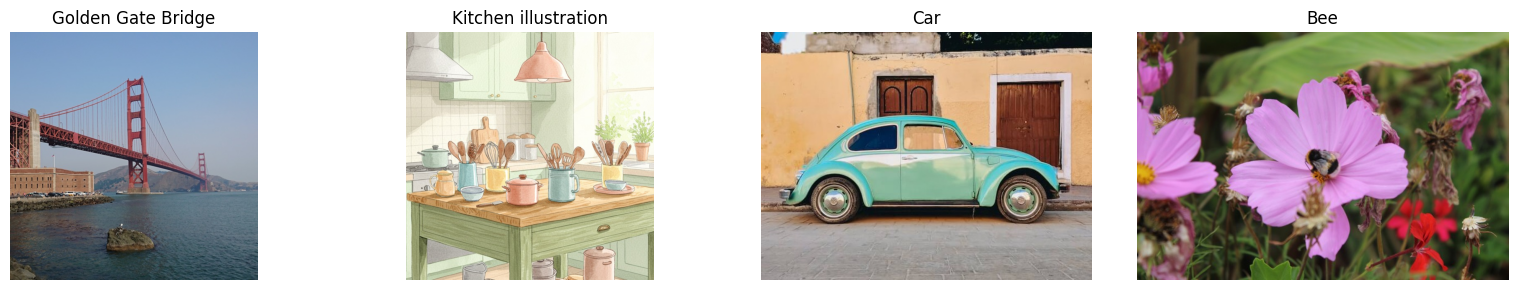

In [5]:
from pathlib import Path
from io import BytesIO
import requests
from PIL import Image
import matplotlib.pyplot as plt

sample_images = [
    ("Golden Gate Bridge", "https://raw.githubusercontent.com/google-gemma/cookbook/refs/heads/main/apps/sample-data/GoldenGate.png"),
    ("Kitchen illustration", "https://raw.githubusercontent.com/google-gemma/cookbook/refs/heads/main/apps/sample-data/kitchen_painting.jpg"),
    ("Car", "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg"),
    ("Bee", "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/bee.jpg"),
]
image_dir = Path("/content/embeddinggemma2_images")
image_dir.mkdir(parents=True, exist_ok=True)

image_records = []
for idx, (name, url) in enumerate(sample_images):
    try:
        r = requests.get(url, timeout=40)
        r.raise_for_status()
        img = Image.open(BytesIO(r.content)).convert("RGB")
        img.thumbnail((600, 600))
        path = image_dir / f"sample_{idx:02d}.jpg"
        img.save(path, quality=92)
        image_records.append({"name": name, "path": str(path)})
    except Exception as e:
        print(f"取得失敗: {name}: {e}")

if not image_records:
    raise RuntimeError("サンプル画像を取得できませんでした。接続を確認してください。")

fig, axes = plt.subplots(1, len(image_records), figsize=(4 * len(image_records), 3))
axes = np.atleast_1d(axes)
for ax, rec in zip(axes, image_records):
    ax.imshow(Image.open(rec["path"]))
    ax.set_title(rec["name"])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. 日本語 → 画像のクロスモーダル検索

**画像は `{"image": ファイルパス}` で入力**し、テキストだけに `SearchQuery` のプロンプトを適用します。

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

検索クエリ: 海にかかる赤い大きな吊り橋の写真


,順位,画像,類似度
0,1,Golden Gate Bridge,0.7322
1,2,Car,0.5384
2,3,Kitchen illustration,0.5300


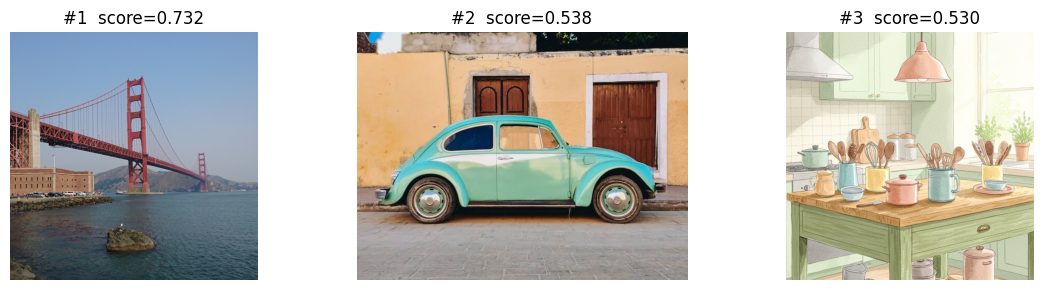

検索クエリ: 調理器具が置かれたキッチンのイラスト


,順位,画像,類似度
0,1,Kitchen illustration,0.7561
1,2,Golden Gate Bridge,0.5243
2,3,Car,0.5216


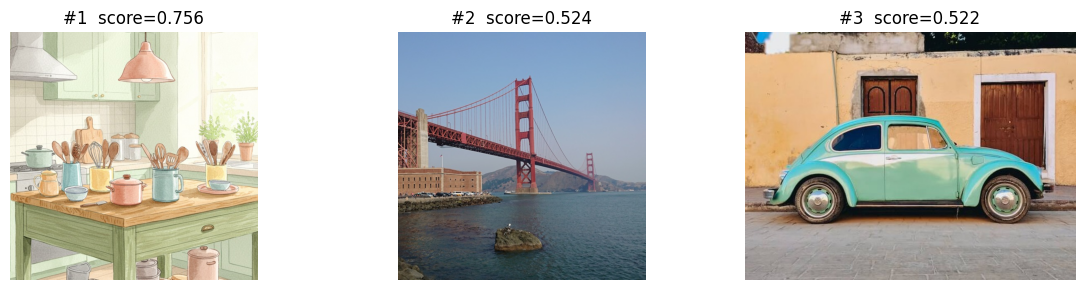

検索クエリ: 青い車が道路に駐車している


,順位,画像,類似度
0,1,Car,0.6473
1,2,Golden Gate Bridge,0.5958
2,3,Bee,0.5380


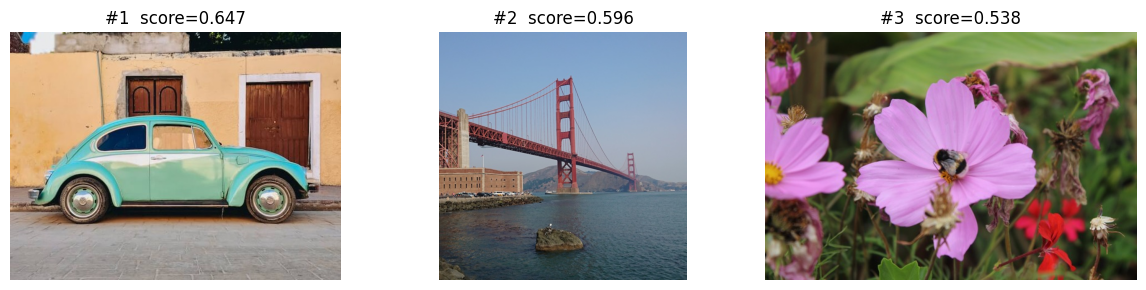

In [8]:
# 画像コーパスのベクトル（データが小さいのでNumPyで検索）
image_vecs = model.encode(
    [{"image": rec["path"]} for rec in image_records],
    batch_size=1,
    normalize_embeddings=True,
    show_progress_bar=True,
)

image_queries = [
    "海にかかる赤い大きな吊り橋の写真",
    "調理器具が置かれたキッチンのイラスト",
    "自動車が写っている写真",
    "花に止まっている蜂の写真",
]

def search_images(query_text: str, top_k: int = 3):
    query_vec = model.encode(
        query_text, prompt_name="SearchQuery", normalize_embeddings=True
    )
    scores = image_vecs @ query_vec
    order = np.argsort(-scores)[:min(top_k, len(scores))]
    print("検索クエリ:", query_text)
    display(pd.DataFrame([
        {"順位": rank, "画像": image_records[i]["name"], "類似度": float(scores[i])}
        for rank, i in enumerate(order, 1)
    ]).round(4))
    fig, axes = plt.subplots(1, len(order), figsize=(4 * len(order), 3))
    axes = np.atleast_1d(axes)
    for rank, (ax, i) in enumerate(zip(axes, order), 1):
        ax.imshow(Image.open(image_records[i]["path"]))
        ax.set_title(f"#{rank}  score={scores[i]:.3f}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return order, scores

# 好きな日本語の質問に変更可能
SEARCH_QUERY = image_queries[0]
_, _ = search_images(SEARCH_QUERY)

# 好きな日本語の質問に変更可能
SEARCH_QUERY = image_queries[1]
_, _ = search_images(SEARCH_QUERY)

SEARCH_QUERY = "青い車が道路に駐車している"
_, _ = search_images(SEARCH_QUERY)

## 6. Embeddingの次元数比較（MRL）

同じ768次元Embeddingを先頭から切り出し、**必ず再度L2正規化**して比較します。

In [10]:
def truncate_and_normalize(x: np.ndarray, dim: int) -> np.ndarray:
    arr = np.asarray(x, dtype=np.float32)[..., :dim]
    denom = np.linalg.norm(arr, axis=-1, keepdims=True)
    return arr / np.maximum(denom, 1e-12)

SEARCH_QUERY = image_queries[0]
base_q = model.encode(SEARCH_QUERY, prompt_name="SearchQuery", normalize_embeddings=True)
mrl_rows = []
for dim in [768, 512, 256, 128]:
    q_d = truncate_and_normalize(base_q, dim)
    docs_d = truncate_and_normalize(image_vecs, dim)
    scores = docs_d @ q_d
    best = int(np.argmax(scores))
    mrl_rows.append({
        "次元数": dim,
        "ベクトル容量(768比)": f"{dim / 768:.1%}",
        "上位画像": image_records[best]["name"],
        "1位スコア": round(float(scores[best]), 4),
        "上位3件": ", ".join(image_records[i]["name"] for i in np.argsort(-scores)[:3]),
    })
display(pd.DataFrame(mrl_rows))
print("注：ここで削減されるのは主にベクトル保存・検索のコストであり、モデル自体の推論コストではありません。")

,次元数,ベクトル容量(768比),上位画像,1位スコア,上位3件
0,768,100.0%,Golden Gate Bridge,0.7324,"Golden Gate Bridge, Car, Kitchen illustration"
1,512,66.7%,Golden Gate Bridge,0.7302,"Golden Gate Bridge, Car, Kitchen illustration"
2,256,33.3%,Golden Gate Bridge,0.7539,"Golden Gate Bridge, Bee, Car"
3,128,16.7%,Golden Gate Bridge,0.8419,"Golden Gate Bridge, Kitchen illustration, Car"


注：ここで削減されるのは主にベクトル保存・検索のコストであり、モデル自体の推論コストではありません。


## 7. 自分の画像をアップロードして検索（任意）

このセルは手動で実行してください。Colabのファイル選択ダイアログから複数画像をアップロードできます。

In [ ]:
from google.colab import files

uploaded = files.upload()  # アップロード画面が出ます
new_count = 0
for filename, content in uploaded.items():
    try:
        img = Image.open(BytesIO(content)).convert("RGB")
        img.thumbnail((600, 600))
        out = image_dir / f"user_{len(image_records):03d}.jpg"
        img.save(out, quality=92)
        image_records.append({"name": filename, "path": str(out)})
        new_count += 1
    except Exception as e:
        print(f"画像を読み込めませんでした: {filename} ({e})")

if new_count:
    # コーパスを更新。初期データが少ないので再計算しても負担は軽い
    image_vecs = model.encode(
        [{"image": r["path"]} for r in image_records],
        batch_size=1, normalize_embeddings=True, show_progress_bar=True
    )
    print(f"{new_count}件追加、総数: {len(image_records)}件")
    user_query = input("探したい画像の説明（例：工場の機械が写った写真）: ").strip() or "工場の機械が写った写真"
    search_images(user_query, top_k=5)
else:
    print("追加画像はありません。")

## 8. 音声 → テキスト検索（任意）

**実行前にセクション2の `ENABLE_AUDIO=True` へ変更し、モデルを再読み込みしてください。** サンプルは英語音声です。

In [ ]:
from IPython.display import Audio

if not ENABLE_AUDIO:
    print("スキップ: セクション2の ENABLE_AUDIO=True でモデルを再読み込みしてください。")
else:
    audio_url = "https://ai.google.dev/gemma/docs/audio/roses-are.wav"
    r = requests.get(audio_url, timeout=40)
    r.raise_for_status()
    audio_path = "/content/embeddinggemma2_sample.wav"
    Path(audio_path).write_bytes(r.content)
    display(Audio(filename=audio_path))

    audio_vec = model.encode({"audio": audio_path}, normalize_embeddings=True)
    audio_captions = [
        "Roses are red, violets are blue.",
        "The sound of a car engine starting.",
        "A person is speaking in English.",
        "Music performed on a piano.",
    ]
    caption_vecs = model.encode(audio_captions, prompt_name="SearchQuery", normalize_embeddings=True)
    scores = caption_vecs @ audio_vec
    display(pd.DataFrame([
        {"テキスト": audio_captions[i], "類似度": float(scores[i])}
        for i in np.argsort(-scores)
    ]).round(4))

## 9. 動画 → テキスト検索（任意）

サンプルMP4を取得し、最大8フレームで検索します。動画のデコードにはtorchcodec/FFmpegが必要です。T4ではフレーム数を少なくして始めてください。

In [ ]:
from IPython.display import Video

RUN_VIDEO_DEMO = False  # 動画を試すときに True に変更して実行
if not RUN_VIDEO_DEMO:
    print("動画実験をスキップしています。RUN_VIDEO_DEMO=True で実行してください。")
else:
    video_url = "https://github.com/bebechien/gemma/raw/refs/heads/main/videos/cat_dozing.mp4"
    r = requests.get(video_url, timeout=90)
    r.raise_for_status()
    video_path = "/content/embeddinggemma2_sample.mp4"
    Path(video_path).write_bytes(r.content)
    display(Video(filename=video_path, embed=True, width=420))

    video_vec = model.encode(
        {"video": video_path},
        normalize_embeddings=True,
        processing_kwargs={
            "video": {
                "max_frames": 8,
                "fps": 1,
                "overflow_strategy": "uniform",
                "add_timestamps": True,
            }
        },
    )
    video_captions = ["A cat sleeping or dozing", "A race car", "A person cooking dinner"]
    video_text_vecs = model.encode(video_captions, prompt_name="SearchQuery", normalize_embeddings=True)
    scores = video_text_vecs @ video_vec
    display(pd.DataFrame([
        {"説明": video_captions[i], "類似度": float(scores[i])}
        for i in np.argsort(-scores)
    ]).round(4))

## 10. 結果の読み方と次のステップ

- **テキスト検索**：異なる表現でも類似事例を発見できるか。
- **画像検索**：テキストと画像が別形式でも類似度を計算できるか。
- **MRL**：768次元に対し256次元でランキングがどれだけ変わるか。
- **音声・動画**：ネイティブ音声・動画入力をテキストと照合できるか。

### Multimodal Incident Intelligence への発展案

1. 障害報告書を `Document` プロンプトで埋め込む。
2. 障害現場の写真・異音・動画を各々ネイティブEmbedding化する。
3. モダリティごとの検索結果を統合し、同じ `incident_id` で事例を集約する。
4. 同一条件のテキストのみ／画像あり／音声あり／時系列ありで Recall@K・MRR・推論時間を比較する。
5. 原因推定は別のLLM/VLMに行わせ、Embeddingの類似度を「原因の確率」と誤解しない。

### 注意点

- 異なるモダリティの類似度はスコア分布が異なり得るため、しきい値を一律に扱わない。
- 初期デモはDB不要でNumPyを使います。データが増えたらQdrantへ移行できます。
- TorchCodec読み込みエラー（`libnvrtc.so.13`）はCPU版TorchCodecの導入で回避します。すでに読み込んだ状態ならランタイムを再起動してください。
- モデル読み込みエラー時は、インストールセルを再実行し、必要ならランタイムを再起動してください。
- `RuntimeError: CUDA out of memory` が出たら音声をOFFにし、画像枚数や動画フレーム数を減らしてください。
- `NaN` が出たら `float16` を使っていないか確認してください。
- モデルのロードや推論はユーザーのColab環境で実施されます。このノートブック自体は静的検証済みで、Colab GPU上での実動作は未実施です。